# Laboratorium 3 — Otwarte dane i wartości odstające

**Eksploracja danych** · dr Paweł Gliwny · WFiIS UŁ

Na tych zajęciach:

1. **Część 1** — pobierzesz dane z portalu otwartych danych Łodzi, wczytasz je, zmienisz ich format, policzysz statystyki zbiorcze i zrobisz proste wykresy.
2. **Część 2** — na danych o pacjentach przejdziesz kolejne kroki wykrywania wartości odstających: od najprostszych do bardziej złożonych.

Miejsca do uzupełnienia oznaczone są `# TODO`. Odpowiedzi na pytania wpisuj w komórkach tekstowych oznaczonych ✍️.

> Notatnik po zajęciach umieść w swoim repozytorium na GitHubie.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [2]:
def upewnij_sie_ze_jest(nazwa_pliku):
    # W Colabie: jeśli pliku nie ma, otwiera okno wgrywania pliku.
    if Path(nazwa_pliku).exists():
        print(f"Plik {nazwa_pliku} jest na miejscu.")
        return
    try:
        from google.colab import files
        print(f"Wgraj plik {nazwa_pliku}:")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Umieść plik {nazwa_pliku} w folderze z notatnikiem.")

---
# Część 1. Dane z portalu otwartych danych Łodzi

Portal: [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl)

Zaczynamy od wspólnego przykładu — pliku `szkolnictwo_wysze.csv` (szkolnictwo wyższe w Łodzi w latach 2012–2024). Pobierz go z portalu albo od prowadzącego i wgraj do Colaba (ikona folderu po lewej lub komórka poniżej).

In [3]:
PLIK_LODZ = "szkolnictwo_wysze.csv"
upewnij_sie_ze_jest(PLIK_LODZ)

Plik szkolnictwo_wysze.csv jest na miejscu.


## 1.1 Wczytanie danych

Zanim wywołasz `read_csv`, obejrzyj surowy plik — pierwsze linie tekstu powiedzą, jaki jest separator.

In [4]:
# podgląd surowego pliku
with open(PLIK_LODZ, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())

name;rok;wartość;zmienna
Szkolnictwo wyższe;2012;22;uczelnie
Szkolnictwo wyższe;2013;22;uczelnie
Szkolnictwo wyższe;2014;23;uczelnie
Szkolnictwo wyższe;2015;21;uczelnie


In [5]:
# separator to średnik — widać to w podglądzie surowego pliku
df = pd.read_csv(PLIK_LODZ, sep=";", encoding="utf-8")

display(df.head())
print("Wymiary:", df.shape)
print(df.dtypes)

,name,rok,wartość,zmienna
0,Szkolnictwo wyższe,2012,22,uczelnie
1,Szkolnictwo wyższe,2013,22,uczelnie
2,Szkolnictwo wyższe,2014,23,uczelnie
3,Szkolnictwo wyższe,2015,21,uczelnie
4,Szkolnictwo wyższe,2016,20,uczelnie


Wymiary: (65, 4)
name         str
rok        int64
wartość    int64
zmienna      str
dtype: object


✍️ **Pytanie:** Jaki jest separator? Czy kolumna `wartość` ma typ liczbowy? Czy nazwy kolumn z polskimi znakami wczytały się poprawnie?

*Odpowiedź:* Separatorem jest średnik (`;`), a nie przecinek — bez `sep=";"` cały wiersz trafiłby do jednej kolumny. Kolumna `wartość` wczytała się jako liczba całkowita (`int64`), bo w pliku nie ma spacji tysięcy ani przecinków dziesiętnych. Plik jest w UTF-8, więc nazwy `wartość`, `mężczyźni`, `ogółem` wyświetlają się poprawnie.

## 1.2 Format długi czy szeroki?

Przypomnienie z wykładu 2: w formacie **długim** każdy wiersz to jedna para (zmienna, wartość); w formacie **szerokim** każda zmienna ma własną kolumnę.

1. Sprawdź, jakie wartości przyjmuje kolumna `zmienna` i ile razy każda występuje.
2. Przekształć dane do formatu szerokiego: wiersze = lata, kolumny = zmienne.

In [6]:
# jakie są zmienne i ile mają wierszy?
print(df["zmienna"].value_counts())

# format szeroki: wiersze = lata, kolumny = zmienne
szeroka = df.pivot(index="rok", columns="zmienna", values="wartość")
szeroka.columns.name = None
szeroka

zmienna
uczelnie             13
ogółem               13
kobiety              13
mężczyźni            13
absolwenci ogółem    13
Name: count, dtype: int64


,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
rok,,,,,
2012,24825,55265,36281,91546,22
2013,22590,50007,33464,83471,22
2014,21343,48220,32456,80676,23
2015,19835,45584,30769,76353,21
2016,17662,44053,29908,73961,20
2017,19281,42990,29029,72019,22
2018,17046,39312,26253,65565,20
2019,15819,38146,26297,64443,19
2020,14082,39170,26155,65325,18


## 1.3 Czy dane są spójne?

Liczba studentów `ogółem` powinna być sumą `kobiety` i `mężczyźni`. Sprawdź to dla każdego roku.

In [7]:
roznica = szeroka["kobiety"] + szeroka["mężczyźni"] - szeroka["ogółem"]
print(roznica)
print("Dane spójne we wszystkich latach:", (roznica == 0).all())

rok
2012    0
2013    0
2014    0
2015    0
2016    0
2017    0
2018    0
2019    0
2020    0
2021    0
2022    0
2023    0
2024    0
dtype: int64
Dane spójne we wszystkich latach: True


## 1.4 Statystyki zbiorcze

1. Policz statystyki opisowe dla wszystkich zmiennych (`describe`).
2. O ile procent zmieniła się każda zmienna między 2012 a 2024 rokiem?
3. Dodaj kolumnę `udzial_kobiet` (udział kobiet wśród studentów) i kolumnę `studenci_na_uczelnie`.

In [8]:
# statystyki opisowe
display(szeroka.describe())

# zmiana procentowa 2012 → 2024
zmiana = (szeroka.loc[2024] / szeroka.loc[2012] - 1) * 100
print("Zmiana 2012 → 2024 [%]:")
print(zmiana.round(1))

# nowe kolumny
szeroka["udzial_kobiet"] = szeroka["kobiety"] / szeroka["ogółem"]
szeroka["studenci_na_uczelnie"] = szeroka["ogółem"] / szeroka["uczelnie"]
szeroka[["udzial_kobiet", "studenci_na_uczelnie"]]

,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
count,13.00,13.00,13.00,13.00,13.00
mean,17780.54,43010.92,28793.92,71804.85,19.54
std,3522.40,5391.05,3524.63,8900.65,2.44
min,14082.00,38146.00,25710.00,64272.00,15.00
25%,14756.00,39170.00,26049.00,65297.00,18.00
50%,17046.00,39958.00,26297.00,66002.00,20.00
75%,19835.00,45584.00,30769.00,76353.00,22.00
max,24825.00,55265.00,36281.00,91546.00,23.00


Zmiana 2012 → 2024 [%]:
absolwenci ogółem   -41.30
kobiety             -30.20
mężczyźni           -29.10
ogółem              -29.80
uczelnie            -31.80
dtype: float64


,udzial_kobiet,studenci_na_uczelnie
rok,,
2012,0.60,4161.18
2013,0.60,3794.14
2014,0.60,3507.65
2015,0.60,3635.86
2016,0.60,3698.05
2017,0.60,3273.59
2018,0.60,3278.25
2019,0.59,3391.74
2020,0.60,3629.17


## 1.5 Wykresy

Narysuj trzy wykresy (najlepiej obok siebie, `plt.subplots(1, 3)`):

1. liczba studentów w czasie — osobne linie dla kobiet i mężczyzn,
2. liczba uczelni w czasie,
3. udział kobiet wśród studentów (oś Y od 0 do 1).

Każdy wykres podpisz: tytuł, opisy osi.

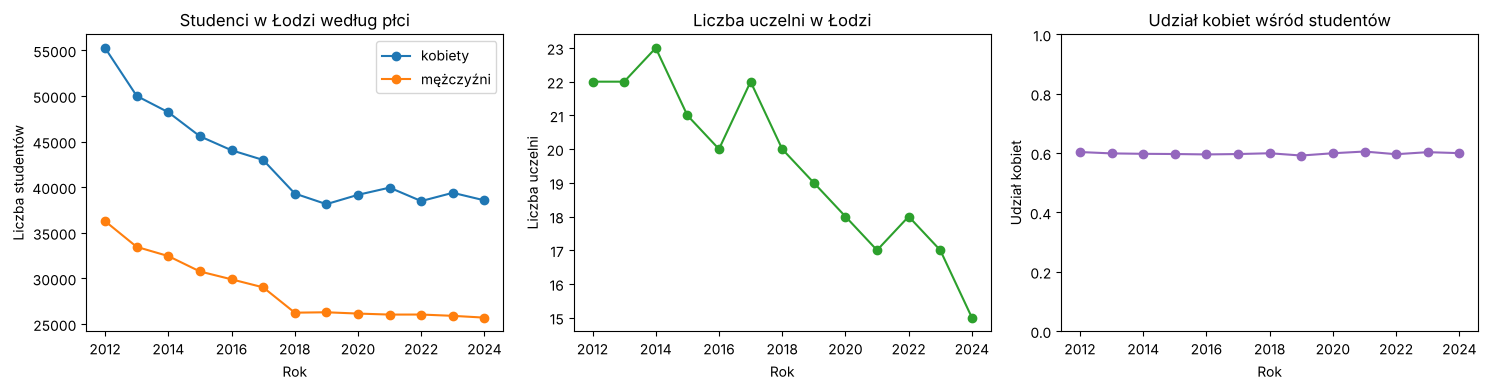

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# wykres 1 — kobiety i mężczyźni
ax = axes[0]
ax.plot(szeroka.index, szeroka["kobiety"], marker="o", label="kobiety")
ax.plot(szeroka.index, szeroka["mężczyźni"], marker="o", label="mężczyźni")
ax.set_title("Studenci w Łodzi według płci")
ax.set_xlabel("Rok")
ax.set_ylabel("Liczba studentów")
ax.legend()

# wykres 2 — uczelnie
ax = axes[1]
ax.plot(szeroka.index, szeroka["uczelnie"], marker="o", color="tab:green")
ax.set_title("Liczba uczelni w Łodzi")
ax.set_xlabel("Rok")
ax.set_ylabel("Liczba uczelni")

# wykres 3 — udział kobiet
ax = axes[2]
ax.plot(szeroka.index, szeroka["udzial_kobiet"], marker="o", color="tab:purple")
ax.set_ylim(0, 1)
ax.set_title("Udział kobiet wśród studentów")
ax.set_xlabel("Rok")
ax.set_ylabel("Udział kobiet")

plt.tight_layout()
plt.show()

✍️ **Wnioski** (3 zdania): co się stało ze szkolnictwem wyższym w Łodzi w latach 2012–2024?

*Odpowiedź:* W latach 2012–2024 liczba studentów w Łodzi spadła o ok. 30% (z 91,5 tys. do 64,3 tys.), przy czym największy spadek nastąpił do 2018 r., a od 2019 r. liczba studentów jest stabilna (ok. 64–66 tys.). Liczba uczelni zmalała z 22 do 15 (−32%), a absolwentów aż o 41%, więc na jedną uczelnię przypada dziś nawet więcej studentów niż w 2012 r. (ok. 4,3 tys.) — rynek uczelni się skonsolidował. Udział kobiet wśród studentów jest niemal stały i wynosi ok. 60% przez cały okres.

## 1.6 Zadanie samodzielne: Twój zbiór z portalu Łodzi

Wybierz **inny** zbiór z [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl) i przejdź te same kroki:

1. Podaj nazwę zbioru, link i datę pobrania.
2. Wczytaj plik (separator? kodowanie? przecinek dziesiętny?).
3. Ustal, czy dane są w formacie długim, czy szerokim; w razie potrzeby przekształć.
4. Sprawdź braki (`isna().sum()`) i spójność danych.
5. Policz statystyki zbiorcze.
6. Zrób 2–3 podpisane wykresy i napisz 2–3 zdania wniosków.

✍️ **Zbiór:** Stopa bezrobocia rejestrowanego (Łódź, 2004–2025), plik `stopa_bezrobocia.csv` · **link:** [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl) · **data pobrania:** 28.10.2026

Zbiór zawiera dwie zmienne: stopę bezrobocia rejestrowanego w Łodzi w % (`ogółem`) oraz tę stopę jako indeks względem Polski (`ogółem (Polska = 100)`).

**Format pliku:** separatorem jest średnik, kodowanie UTF-8, a liczby zapisane są z **przecinkiem dziesiętnym** (`18,4`), więc trzeba podać `decimal=","` — bez tego kolumna `wartość` wczytałaby się jako tekst. Kolumna ze zmiennymi nazywa się tu `zmienne` (a nie `zmienna` jak w poprzednim zbiorze). Dane są w formacie **długim**.

In [10]:
PLIK_BEZROBOCIE = "stopa_bezrobocia.csv"
upewnij_sie_ze_jest(PLIK_BEZROBOCIE)

with open(PLIK_BEZROBOCIE, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())

bezr = pd.read_csv(PLIK_BEZROBOCIE, sep=";", decimal=",", encoding="utf-8")
display(bezr.head())
print("Wymiary:", bezr.shape)
print(bezr.dtypes)
print("\nBraki:\n", bezr.isna().sum())
print("\nZmienne:\n", bezr["zmienne"].value_counts())

Plik stopa_bezrobocia.csv jest na miejscu.
﻿name;rok;wartość;zmienne
Stopa bezrobocia rejestrowanego;2004;18,4;ogółem
Stopa bezrobocia rejestrowanego;2005;16,4;ogółem
Stopa bezrobocia rejestrowanego;2006;11,7;ogółem
Stopa bezrobocia rejestrowanego;2007;8,5;ogółem


,name,rok,wartość,zmienne
0,Stopa bezrobocia rejestrowanego,2004,18.40,ogółem
1,Stopa bezrobocia rejestrowanego,2005,16.40,ogółem
2,Stopa bezrobocia rejestrowanego,2006,11.70,ogółem
3,Stopa bezrobocia rejestrowanego,2007,8.50,ogółem
4,Stopa bezrobocia rejestrowanego,2008,6.80,ogółem


Wymiary: (44, 4)
name           str
rok          int64
wartość    float64
zmienne        str
dtype: object

Braki:
 name       0
rok        0
wartość    0
zmienne    0
dtype: int64

Zmienne:
 zmienne
ogółem                   22
ogółem (Polska = 100)    22
Name: count, dtype: int64


Braki po pivocie:
 stopa_lodz      0
indeks_PL100    0
dtype: int64
Lata ciągłe 2004–2025: True
Duplikaty (rok, zmienna): 0
Stopa w zakresie 0–100%: True
Odtworzona stopa PL 2004 i 2023: [19.0, 5.1]


,stopa_lodz,indeks_PL100,stopa_polska
rok,,,
2004,18.40,96.80,19.01
2005,16.40,93.20,17.60
2006,11.70,79.10,14.79
2007,8.50,75.90,11.20
2008,6.80,71.60,9.50
2009,9.60,79.30,12.11
2010,10.00,80.60,12.41
2011,11.00,88.00,12.50
2012,12.00,89.60,13.39


,stopa_lodz,indeks_PL100,stopa_polska
count,22.00,22.00,22.00
mean,8.73,89.51,9.81
std,3.87,7.84,4.26
min,4.40,71.60,5.10
25%,5.58,86.35,5.72
50%,8.20,92.05,9.60
75%,10.93,95.42,12.48
max,18.40,100.00,19.01


Zmiana 2004 → 2025 [%]:
stopa_lodz     -70.10
indeks_PL100    -0.30
stopa_polska   -70.00
dtype: float64
Rok z najniższą stopą w Łodzi: 2023 | najwyższą: 2004


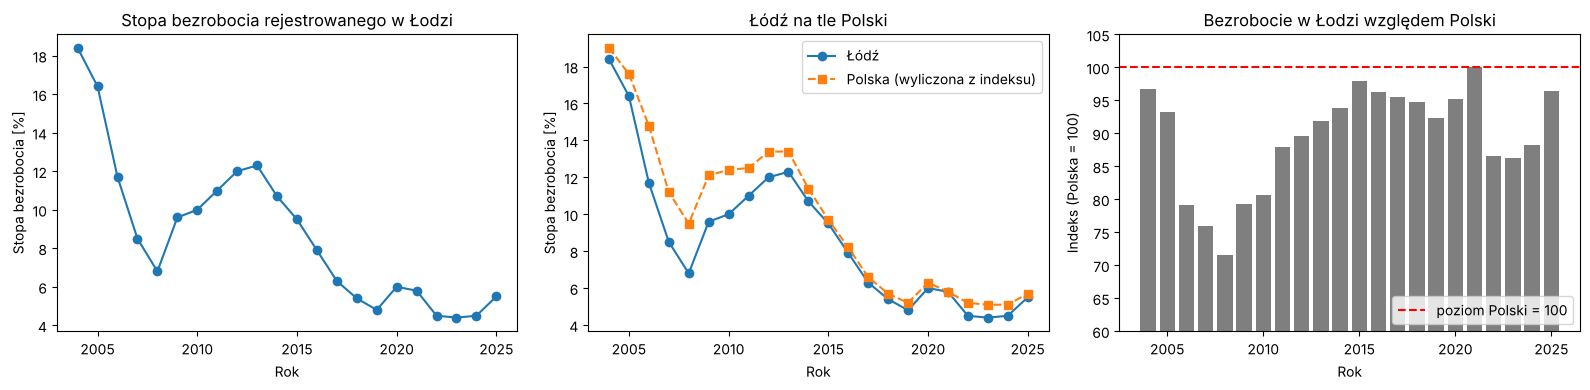

In [11]:
# format długi → szeroki
bezr_sz = bezr.pivot(index="rok", columns="zmienne", values="wartość")
bezr_sz.columns = ["stopa_lodz", "indeks_PL100"]
bezr_sz.columns.name = None

# spójność: komplet lat, brak duplikatów, wartości w sensownym zakresie
print("Braki po pivocie:\n", bezr_sz.isna().sum())
print("Lata ciągłe 2004–2025:", list(bezr_sz.index) == list(range(2004, 2026)))
print("Duplikaty (rok, zmienna):", bezr.duplicated(["rok", "zmienne"]).sum())
print("Stopa w zakresie 0–100%:", bezr_sz["stopa_lodz"].between(0, 100).all())

# z indeksu można odtworzyć stopę dla Polski: stopa_PL = stopa_Łódź / indeks * 100
bezr_sz["stopa_polska"] = bezr_sz["stopa_lodz"] / bezr_sz["indeks_PL100"] * 100
# kontrola z danymi GUS: stopa bezrobocia w Polsce wynosiła 19,0% w 2004 r. i 5,1% w 2023 r.
print("Odtworzona stopa PL 2004 i 2023:", bezr_sz.loc[[2004, 2023], "stopa_polska"].round(1).tolist())
display(bezr_sz)

# statystyki zbiorcze
display(bezr_sz.describe())
print("Zmiana 2004 → 2025 [%]:")
print(((bezr_sz.loc[2025] / bezr_sz.loc[2004] - 1) * 100).round(1))
print("Rok z najniższą stopą w Łodzi:", bezr_sz["stopa_lodz"].idxmin(), "| najwyższą:", bezr_sz["stopa_lodz"].idxmax())

# wykresy
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

ax = axes[0]
ax.plot(bezr_sz.index, bezr_sz["stopa_lodz"], marker="o")
ax.set_title("Stopa bezrobocia rejestrowanego w Łodzi")
ax.set_xlabel("Rok")
ax.set_ylabel("Stopa bezrobocia [%]")

ax = axes[1]
ax.plot(bezr_sz.index, bezr_sz["stopa_lodz"], marker="o", label="Łódź")
ax.plot(bezr_sz.index, bezr_sz["stopa_polska"], marker="s", linestyle="--", label="Polska (wyliczona z indeksu)")
ax.set_title("Łódź na tle Polski")
ax.set_xlabel("Rok")
ax.set_ylabel("Stopa bezrobocia [%]")
ax.legend()

ax = axes[2]
ax.bar(bezr_sz.index, bezr_sz["indeks_PL100"], color="tab:gray")
ax.axhline(100, color="red", linestyle="--", label="poziom Polski = 100")
ax.set_ylim(60, 105)
ax.set_title("Bezrobocie w Łodzi względem Polski")
ax.set_xlabel("Rok")
ax.set_ylabel("Indeks (Polska = 100)")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

✍️ **Wnioski:** Stopa bezrobocia rejestrowanego w Łodzi spadła z 18,4% w 2004 r. do 4,4–4,5% w latach 2022–2024 (o ok. 70% do 2025 r.), choć spadek przerwały wzrosty po kryzysie 2008 r. (do 12,3% w 2013 r.), w pandemii (2020) i ponownie w 2025 r. (5,5%). Przez cały okres bezrobocie w Łodzi było niższe lub równe średniej krajowej (indeks 71,6–100), a największa przewaga przypadała na lata 2007–2008. W ostatnich latach przewaga ta się kurczy: w 2025 r. indeks wzrósł do 96,5, więc stopa w Łodzi zbliżyła się do krajowej.

---
# Część 2. Wartości odstające — dane o pacjentach

Zbiór: 3000 pacjentów z kolumnami `age` (wiek), `bmi`, `avg_glucose_level` (średni poziom glukozy we krwi, mg/dl), `hypertension`, `heart_disease`, `work_type` (rodzaj pracy), `smoking_status` (palenie), `stroke` (udar: 1/0) i kilkoma innymi.

> ⚠️ To **dane syntetyczne** — wygenerowane i celowo „zepsute” do ćwiczeń. Nie wyciągamy z nich wniosków medycznych.
>
> Źródło: deepsense.ai, *EDA Benchmark*, zadanie `identify-unusual-values` ([github.com/deepsense-ai/eda-benchmark](https://github.com/deepsense-ai/eda-benchmark)), licencja CC BY-NC-ND 4.0.

Plan — od najprostszej metody do najbardziej złożonej:

| Krok | Metoda |
|---|---|
| 1 | wartości niemożliwe — progi z wiedzy dziedzinowej |
| 2 | wartości skrajne w jednej zmiennej — wykresy, potem IQR, z-score, MAD |
| 3 | nielogiczne kombinacje kategorii — reguły |
| 4 | nietypowe kombinacje liczb — odległość od środka |
| 5 | decyzja: co zrobić z każdą grupą |

In [12]:
URL = ("https://raw.githubusercontent.com/deepsense-ai/eda-benchmark/main/"
       "tasks/identify-unusual-values/environment/dataset/synthetic_stroke_data.csv")

pacjenci = pd.read_csv(URL)
oryginal = pacjenci.copy()      # kopia surowych danych — przyda się na końcu
pacjenci.head()

,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,A456281,Male,25.00,0,0,False,student,Urban,77.47,35.66,formerly smoked,0
1,A730553,Male,16.00,0,0,True,student,Urban,83.78,34.76,never smoked,0
2,A800980,Male,19.00,0,0,True,Private,Urban,91.65,25.38,never smoked,0
3,A433166,Male,35.00,0,0,True,Self-employed,Urban,97.09,21.26,never smoked,0
4,A114521,Male,15.00,0,0,True,student,Urban,89.17,22.27,formerly smoked,0


## 2.0 Pierwszy rzut oka

Wyświetl statystyki opisowe kolumn liczbowych `age`, `bmi`, `avg_glucose_level` i narysuj ich histogramy.

,age,bmi,avg_glucose_level
count,3000.00,3000.00,3000.00
mean,45.25,26.29,134.00
std,20.83,15.88,181.27
min,0.67,-5.20,-21.40
25%,28.00,21.28,85.59
50%,49.00,24.70,101.40
75%,63.00,28.88,127.43
max,80.00,105.60,1254.60


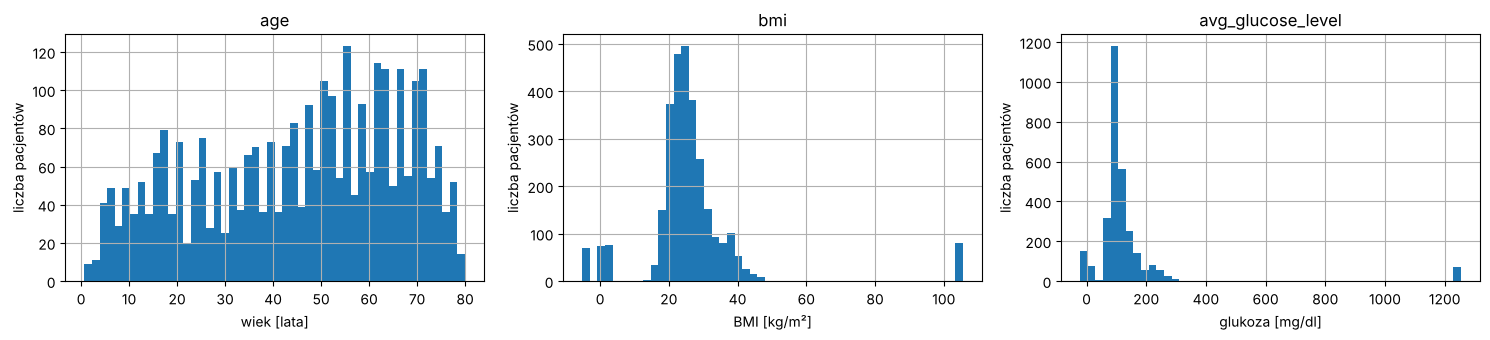

In [13]:
LICZBOWE = ["age", "bmi", "avg_glucose_level"]

# statystyki opisowe
display(pacjenci[LICZBOWE].describe())

# histogramy
axes = pacjenci[LICZBOWE].hist(bins=50, figsize=(15, 3.5), layout=(1, 3))
for ax, opis in zip(axes.ravel(), ["wiek [lata]", "BMI [kg/m²]", "glukoza [mg/dl]"]):
    ax.set_xlabel(opis)
    ax.set_ylabel("liczba pacjentów")
plt.tight_layout()
plt.show()

✍️ **Pytanie:** Które wartości minimalne i maksymalne są w ogóle *możliwe* u człowieka?

*Odpowiedź:* Wiek jest w porządku: od ok. 8 miesięcy (0,67 roku) do 80 lat. BMI ma niemożliwe minimum −5,2 (BMI nie może być ujemne ani równe 0) i maksimum 105,6, które jest poza zakresem obserwowanym w praktyce. Glukoza ma minimum −21,4 mg/dl (ujemne stężenie nie istnieje) i maksimum 1254,6 mg/dl, wartość praktycznie niezgodną z życiem jako średni poziom. Na histogramach widać, że te wartości tworzą wąskie „słupki” (np. −5,2; 0; 3,4; 105,6 dla BMI), co wskazuje na sztuczne, powtarzające się kody błędu.

## 2.1 Krok 1: wartości niemożliwe

Przyjmujemy progi:

| Zmienna | Zakres możliwy |
|---|---|
| `bmi` | 10–60 |
| `avg_glucose_level` | 20–800 mg/dl |
| `age` | 0–120 lat |

Wartości spoza zakresu to **szum techniczny**, a nie rzadcy pacjenci — zamieniamy je na `NaN`.

1. Utwórz maski `zle_bmi`, `zla_glukoza`, `zly_wiek` (przyda się `Series.between`).
2. Policz, ile wartości jest niemożliwych w każdej kolumnie i ilu pacjentów ma co najmniej jedną taką wartość.
3. Zamień niemożliwe wartości na `NaN`.

In [14]:
# maski (between zwraca False dla NaN, więc dodatkowo wymagamy notna)
zle_bmi = ~pacjenci["bmi"].between(10, 60) & pacjenci["bmi"].notna()
zla_glukoza = ~pacjenci["avg_glucose_level"].between(20, 800) & pacjenci["avg_glucose_level"].notna()
zly_wiek = ~pacjenci["age"].between(0, 120) & pacjenci["age"].notna()

# liczebności
print("Niemożliwe BMI:     ", zle_bmi.sum())
print("Niemożliwa glukoza: ", zla_glukoza.sum())
print("Niemożliwy wiek:    ", zly_wiek.sum())
niemozliwa = zle_bmi | zla_glukoza | zly_wiek
print("Pacjenci z ≥1 niemożliwą wartością:", niemozliwa.sum())
print("Niemożliwe wartości BMI:", sorted(pacjenci.loc[zle_bmi, "bmi"].unique()))
print("Niemożliwe wartości glukozy:", sorted(pacjenci.loc[zla_glukoza, "avg_glucose_level"].unique()))

# zamiana na NaN
pacjenci.loc[zle_bmi, "bmi"] = np.nan
pacjenci.loc[zla_glukoza, "avg_glucose_level"] = np.nan
pacjenci.loc[zly_wiek, "age"] = np.nan

Niemożliwe BMI:      300
Niemożliwa glukoza:  300
Niemożliwy wiek:     0
Pacjenci z ≥1 niemożliwą wartością: 560
Niemożliwe wartości BMI: [np.float64(-5.2), np.float64(0.0), np.float64(3.4), np.float64(105.6)]
Niemożliwe wartości glukozy: [np.float64(-21.4), np.float64(0.0), np.float64(5.0), np.float64(1254.6)]


,age,bmi,avg_glucose_level
count,3000.00,2700.00,2700.00
mean,45.25,26.12,116.84
std,20.83,5.84,44.45
min,0.67,13.57,44.76
25%,28.00,21.94,89.47
50%,49.00,24.98,103.09
75%,63.00,28.85,127.84
max,80.00,47.62,332.91


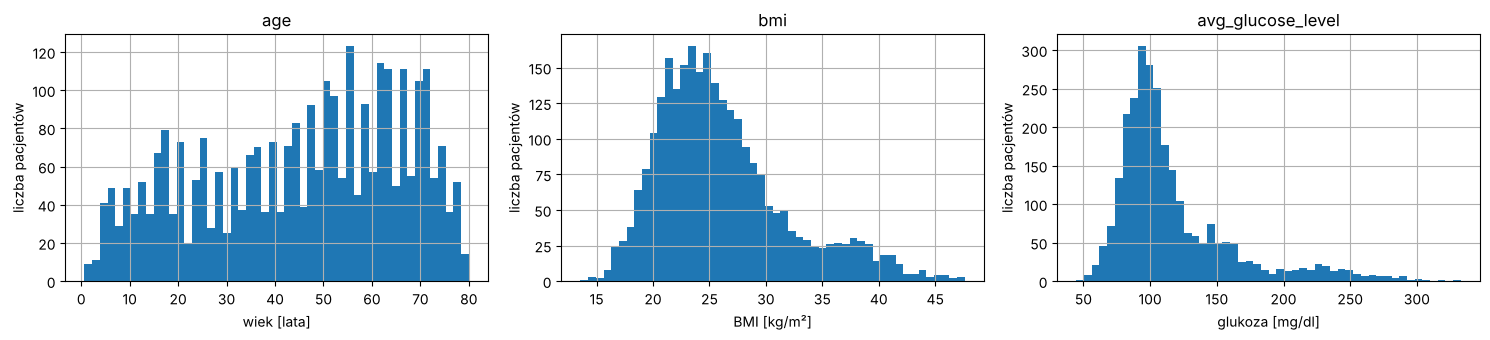

In [15]:
display(pacjenci[LICZBOWE].describe())

axes = pacjenci[LICZBOWE].hist(bins=50, figsize=(15, 3.5), layout=(1, 3))
for ax, opis in zip(axes.ravel(), ["wiek [lata]", "BMI [kg/m²]", "glukoza [mg/dl]"]):
    ax.set_xlabel(opis)
    ax.set_ylabel("liczba pacjentów")
plt.tight_layout()
plt.show()

# Po zamianie: BMI 13,6–47,6, glukoza 44,8–332,9 mg/dl; odchylenie standardowe glukozy spadło
# ze 181 do 44, a BMI z 15,9 do 5,8 — kilka błędnych kodów mocno zawyżało rozrzut.
# Histogramy pokazują teraz prawdziwe kształty: BMI lekko, a glukoza silnie prawoskośna.

## 2.2 Krok 2a: wartości skrajne w jednej zmiennej — wykresy

Zanim cokolwiek policzysz, **obejrzyj** dane.

1. Narysuj obok siebie poziome wykresy pudełkowe dla `bmi` i `avg_glucose_level` (`plt.subplots(1, 2)`, `ax.boxplot(..., orientation="horizontal")`). Pamiętaj o `dropna()`.
2. Narysuj obok siebie dwa wykresy punktowe: `age` × `avg_glucose_level` i `age` × `bmi`.

Podpisz osie (z jednostkami) i nadaj tytuły.

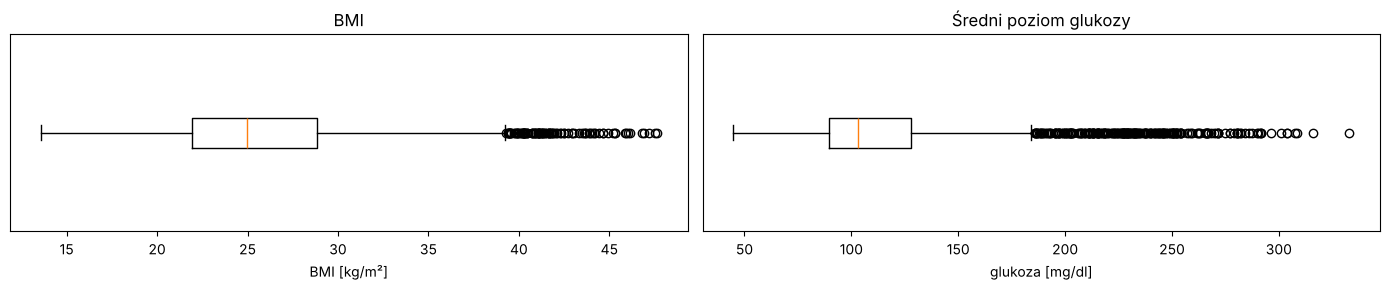

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3))

axes[0].boxplot(pacjenci["bmi"].dropna(), orientation="horizontal")
axes[0].set_title("BMI")
axes[0].set_xlabel("BMI [kg/m²]")
axes[0].set_yticks([])

axes[1].boxplot(pacjenci["avg_glucose_level"].dropna(), orientation="horizontal")
axes[1].set_title("Średni poziom glukozy")
axes[1].set_xlabel("glukoza [mg/dl]")
axes[1].set_yticks([])

plt.tight_layout()
plt.show()

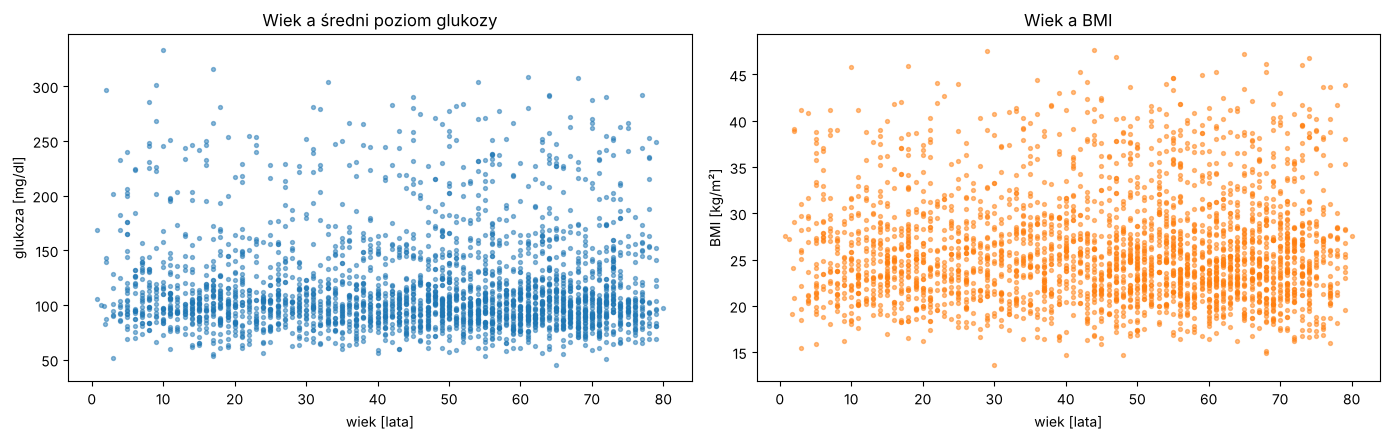

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].scatter(pacjenci["age"], pacjenci["avg_glucose_level"], s=8, alpha=0.5)
axes[0].set_title("Wiek a średni poziom glukozy")
axes[0].set_xlabel("wiek [lata]")
axes[0].set_ylabel("glukoza [mg/dl]")

axes[1].scatter(pacjenci["age"], pacjenci["bmi"], s=8, alpha=0.5, color="tab:orange")
axes[1].set_title("Wiek a BMI")
axes[1].set_xlabel("wiek [lata]")
axes[1].set_ylabel("BMI [kg/m²]")

plt.tight_layout()
plt.show()

✍️ **Pytania:**
1. Dla której zmiennej jest więcej punktów poza wąsami? Czy leżą po obu stronach pudełka, czy tylko po jednej?
2. Na wykresie punktowym: czy wysokie wartości glukozy występują tylko w określonym wieku? Czy 10-latek ze średnią glukozą ponad 300 mg/dl to błąd, czy rzadki przypadek?

*Odpowiedź:*
1. Więcej punktów poza wąsami ma glukoza (235 wobec 100 dla BMI). W obu zmiennych leżą one tylko po prawej stronie (wartości wysokie), co jest skutkiem prawoskośności rozkładów.
2. Nie — wysokie wartości glukozy (> 200 mg/dl) występują równomiernie w całym zakresie wieku, także u dzieci (u 19 osób poniżej 18 lat glukoza przekracza 300 mg/dl), a średnia glukozy w grupach wiekowych jest prawie taka sama. W prawdziwych danych 10-latek z glukozą > 300 mg/dl byłby rzadkim, ale możliwym przypadkiem (np. nieleczona cukrzyca typu 1), więc nie jest to wartość niemożliwa. Tutaj, przy braku związku glukozy z wiekiem, to raczej cecha syntetycznego generatora niż dowód na błąd — taki rekord warto oznaczyć do weryfikacji, a nie automatycznie usuwać.

## 2.3 Krok 2b: wartości skrajne w jednej zmiennej — metody liczbowe

Napisz trzy funkcje, które dla kolumny `s` zwracają maskę (`True` = wartość odstająca):

- `maska_iqr(s, k=1.5)` — poza $[Q_1 - k \cdot IQR,\; Q_3 + k \cdot IQR]$,
- `maska_z(s, prog=3)` — $|z| > prog$, gdzie $z = (x - \bar{x}) / s$,
- `maska_mad(s, prog=3.5)` — odporny z-score $|0{,}6745 \cdot (x - \text{med}) / \text{MAD}| > prog$.

Braki (`NaN`) nie powinny być oznaczane jako odstające.

In [18]:
def maska_iqr(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)      # NaN → False

def maska_z(s, prog=3):
    z = (s - s.mean()) / s.std()
    return z.abs() > prog                                 # NaN → False

def maska_mad(s, prog=3.5):
    med = s.median()
    mad = (s - med).abs().median()
    return (0.6745 * (s - med) / mad).abs() > prog        # NaN → False

Zbuduj tabelę porównawczą: wiersze = zmienne (`age`, `bmi`, `avg_glucose_level`), kolumny = metody (IQR 1,5, IQR 3, z-score, MAD), wartości = liczba wykrytych obserwacji. Dodaj kolumnę ze **skośnością** (`skew`).

In [19]:
porownanie = pd.DataFrame({
    kol: {
        "IQR 1,5": maska_iqr(pacjenci[kol]).sum(),
        "IQR 3": maska_iqr(pacjenci[kol], k=3).sum(),
        "z-score": maska_z(pacjenci[kol]).sum(),
        "MAD": maska_mad(pacjenci[kol]).sum(),
        "skośność": pacjenci[kol].skew(),
    }
    for kol in LICZBOWE
}).T
porownanie[["IQR 1,5", "IQR 3", "z-score", "MAD"]] = porownanie[["IQR 1,5", "IQR 3", "z-score", "MAD"]].astype(int)
porownanie

,"IQR 1,5",IQR 3,z-score,MAD,skośność
age,0,0,0,0,-0.33
bmi,100,0,23,33,0.99
avg_glucose_level,235,81,62,223,1.80


✍️ **Pytanie:** Dlaczego dla glukozy metody dają tak różne wyniki, a dla wieku żadna nic nie wykrywa? Spójrz na skośność i histogramy.

*Odpowiedź:* Glukoza jest silnie prawoskośna (skośność ≈ 1,8): ma wąski „rdzeń” wokół 80–130 mg/dl i długi ogon do ~330 mg/dl (drugi garb wysokich wartości). Metody oparte na kwartylach i medianie (IQR 1,5 → 235, MAD → 223) mierzą rozrzut na podstawie wąskiego rdzenia, więc oznaczają prawie cały ogon. Z-score (62) używa średniej i odchylenia standardowego, które sam ogon zawyża, więc próg przesuwa się w prawo; IQR 3 (81) jest po prostu łagodniejszym progiem. Wszystkie te metody zakładają symetryczny rozkład, dlatego na skośnych danych dają różne wyniki. Wiek ma rozkład ograniczony (0–80 lat), szeroki, bez ogonów i lekko lewoskośny (−0,33), więc żadna wartość nie jest daleko od środka w stosunku do rozrzutu.

### Wykres: zaznacz wartości odstające

Powtórz wykres punktowy `age` × `avg_glucose_level`, ale tym razem:

- zaznacz innym kolorem pacjentów, których glukoza jest odstająca według `maska_iqr` (i podaj ich liczbę w legendzie),
- narysuj poziomą linię przerywaną na górnej granicy $Q_3 + 1{,}5 \cdot IQR$ (`ax.axhline`).

Sprawdź: czy liczba punktów nad linią zgadza się z liczbą punktów poza wąsem na wykresie pudełkowym?

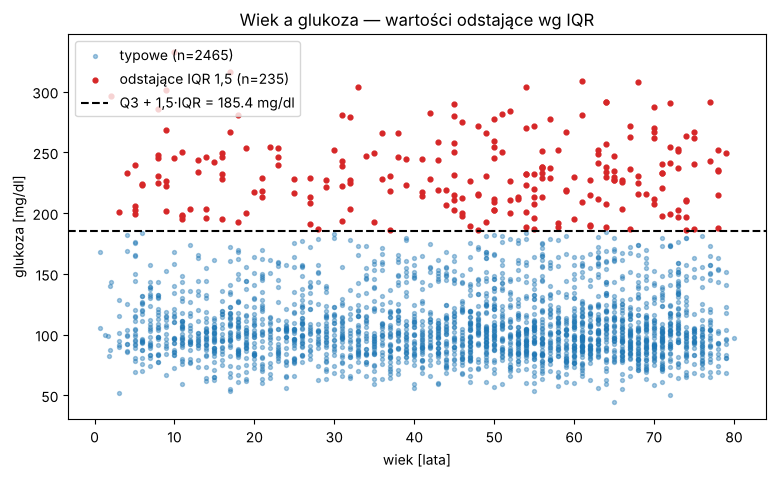

Punkty nad linią: 235 | odstające wg IQR: 235


In [20]:
gl = pacjenci["avg_glucose_level"]
odst = maska_iqr(gl)
q1, q3 = gl.quantile([0.25, 0.75])
gorna = q3 + 1.5 * (q3 - q1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(pacjenci.loc[~odst, "age"], gl[~odst], s=8, alpha=0.4, label=f"typowe (n={(~odst & gl.notna()).sum()})")
ax.scatter(pacjenci.loc[odst, "age"], gl[odst], s=12, color="tab:red", label=f"odstające IQR 1,5 (n={odst.sum()})")
ax.axhline(gorna, color="black", linestyle="--", label=f"Q3 + 1,5·IQR = {gorna:.1f} mg/dl")
ax.set_title("Wiek a glukoza — wartości odstające wg IQR")
ax.set_xlabel("wiek [lata]")
ax.set_ylabel("glukoza [mg/dl]")
ax.legend()
plt.show()

print("Punkty nad linią:", (gl > gorna).sum(), "| odstające wg IQR:", odst.sum())
# Zgadza się: wszystkie odstające leżą nad górną granicą (pod dolną nie ma żadnego),
# a to dokładnie punkty poza prawym wąsem wykresu pudełkowego.

### Czy wartość odstająca niesie informację?

Wysoki poziom glukozy może być związany z udarem. Porównaj odsetek udarów (`stroke`) wśród pacjentów z glukozą odstającą (IQR 1,5) i wśród pozostałych. Narysuj wykres pudełkowy glukozy w podziale na `stroke`.

,odsetek udarów,liczba udarów,liczba pacjentów
avg_glucose_level,,,
glukoza odstająca,0.22,51,235
pozostali,0.22,606,2765


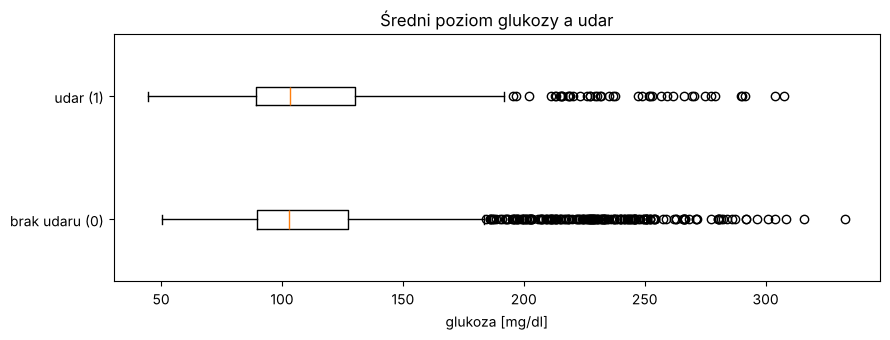

In [21]:
# odsetek udarów w obu grupach
gl_odst = maska_iqr(pacjenci["avg_glucose_level"])
udary = pacjenci.groupby(gl_odst.map({True: "glukoza odstająca", False: "pozostali"}))["stroke"].agg(["mean", "sum", "size"])
udary.columns = ["odsetek udarów", "liczba udarów", "liczba pacjentów"]
display(udary)

# boxplot glukozy w podziale na stroke
fig, ax = plt.subplots(figsize=(9, 3.5))
dane = [pacjenci.loc[pacjenci["stroke"] == k, "avg_glucose_level"].dropna() for k in [0, 1]]
ax.boxplot(dane, orientation="horizontal", tick_labels=["brak udaru (0)", "udar (1)"])
ax.set_title("Średni poziom glukozy a udar")
ax.set_xlabel("glukoza [mg/dl]")
plt.tight_layout()
plt.show()

✍️ **Pytanie:** Czy pacjentów z wysoką glukozą należy usunąć z danych, jeśli chcemy przewidywać udar?

*Odpowiedź:* Nie. To prawdziwe (możliwe biologicznie) obserwacje, stanowiące ok. 9% danych, a w realnych danych wysoka glukoza jest znanym czynnikiem ryzyka udaru — usunięcie ich wycięłoby właśnie tę informację i model nie nauczyłby się przewidywać udaru u pacjentów najbardziej narażonych. W tym syntetycznym zbiorze odsetek udarów jest w obu grupach taki sam (ok. 22%), więc glukoza nie niesie tu informacji o udarze, ale to wniosek o tym zbiorze, a nie powód do usuwania. Lepiej je zostawić i co najwyżej zmniejszyć wpływ ogona (logarytm, przycięcie) albo dodać flagę „wysoka glukoza”.

## 2.4 Krok 3: nielogiczne kombinacje kategorii

Każda wartość osobno może być poprawna („dziecko”, „pali”), a niemożliwa jest dopiero ich kombinacja.

1. Zrób tabelę krzyżową `work_type` × `smoking_status` (`pd.crosstab`). Co jest podejrzane?
2. Utwórz maski:
   - `dziecko_pali` — `work_type == "children"` i `smoking_status` to `"smokes"` lub `"formerly smoked"`,
   - `maluch_student` — wiek ≤ 3 lata i `work_type == "student"`.
3. Wyświetl znalezionych pacjentów.

In [22]:
# tabela krzyżowa
display(pd.crosstab(pacjenci["work_type"], pacjenci["smoking_status"]))

# maski
dziecko_pali = (pacjenci["work_type"] == "children") & pacjenci["smoking_status"].isin(["smokes", "formerly smoked"])
maluch_student = (pacjenci["age"] <= 3) & (pacjenci["work_type"] == "student")

print("Dzieci palące / byli palacze:", dziecko_pali.sum())
print("Maluchy (≤ 3 lata) jako studenci:", maluch_student.sum())
pacjenci.loc[dziecko_pali | maluch_student, ["patient_id", "age", "work_type", "smoking_status", "bmi", "avg_glucose_level"]]

smoking_status,Unknown,formerly smoked,never smoked,smokes
work_type,,,,
Govt_job,16,63,94,67
Never_worked,1,30,36,35
Private,76,440,585,445
Self-employed,18,137,166,131
children,17,0,274,15
student,22,67,190,75


Dzieci palące / byli palacze: 15
Maluchy (≤ 3 lata) jako studenci: 1


,patient_id,age,work_type,smoking_status,bmi,avg_glucose_level
52,A582477,1.80,student,formerly smoked,24.05,82.20
111,A678646,9.00,children,smokes,22.24,96.59
290,A844121,13.00,children,smokes,20.14,163.31
336,A135365,12.00,children,smokes,27.15,135.59
352,A810636,14.00,children,smokes,NaN,203.26
361,A843508,2.00,children,smokes,39.11,143.14
578,A161666,3.00,children,smokes,15.47,NaN
600,A623587,10.00,children,smokes,20.93,NaN
613,A892803,13.00,children,smokes,25.04,132.17
741,A560170,13.00,children,smokes,25.59,243.95


Podejrzane w tabeli krzyżowej: 15 osób z `work_type = children` ma status `smokes` (w kategorii dzieci nie ma ani jednego „formerly smoked”, za to są „smokes” — także u 2–3-latków). Dodatkowo 1,8-roczne dziecko jest oznaczone jako `student` i „formerly smoked”.

✍️ **Pytanie:** Czy IQR albo z-score mogłyby wykryć te przypadki? Dlaczego?

*Odpowiedź:* Nie. IQR i z-score działają na jednej zmiennej liczbowej i szukają wartości daleko od środka rozkładu, a tu każda wartość osobno jest typowa: wiek 2–14 lat jest normalny, „smokes” i „student” to częste kategorie. Błąd tkwi dopiero w kombinacji kilku zmiennych (w tym kategorycznych, dla których IQR/z-score w ogóle nie mają sensu), więc wykrywa się go regułami z wiedzy dziedzinowej.

## 2.5 Krok 4: nietypowe kombinacje liczb — odległość od środka

Liczymy kwadrat **odległości euklidesowej** każdego pacjenta od środka danych, po standaryzacji cech:

$$d^2 = \sum_j \left(\frac{x_j - \bar{x}_j}{s_j}\right)^2$$

Dla danych o rozkładzie normalnym $d^2$ ma rozkład $\chi^2$ z $p$ stopniami swobody ($p$ = liczba cech), więc próg bierzemy z kwantyla 0,99.

1. Weź kolumny `LICZBOWE` bez braków (`dropna`) → `X`.
2. Wystandaryzuj je i policz `d2`.
3. Wyznacz próg `chi2.ppf(0.99, df=3)` i policz, ilu pacjentów go przekracza.
4. Sprawdź, **która cecha** ma największy udział w $d^2$ u tych pacjentów (`idxmax(axis=1)` na kwadratach z-score'ów).

In [23]:
from scipy.stats import chi2

X = pacjenci[LICZBOWE].dropna()
Z = (X - X.mean()) / X.std()
d2 = (Z ** 2).sum(axis=1)
prog = chi2.ppf(0.99, df=3)

odlegli = d2 > prog
print(f"Pacjenci z kompletem cech: {len(X)}")
print(f"Próg chi2(0,99; 3) = {prog:.2f}")
print(f"Przekraczających próg: {odlegli.sum()} (oczekiwane przy normalności ≈ {0.01 * len(X):.0f})")

print("\nCecha o największym udziale w d²:")
print((Z[odlegli] ** 2).idxmax(axis=1).value_counts())

Pacjenci z kompletem cech: 2440
Próg chi2(0,99; 3) = 11.34
Przekraczających próg: 73 (oczekiwane przy normalności ≈ 24)

Cecha o największym udziale w d²:
avg_glucose_level    54
bmi                  19
Name: count, dtype: int64


Glukoza jest silnie prawoskośna, więc odległość wskazuje głównie jej długi ogon. Powtórz obliczenia po zlogarytmowaniu glukozy (`np.log`) i porównaj liczbę odstających. Narysuj wykres punktowy `bmi` × `avg_glucose_level`, zaznaczając pacjentów odstających po transformacji.

Odstający przed logarytmem: 73
Odstający po logarytmie:   31
Cecha o największym udziale po logarytmie:
bmi                  22
avg_glucose_level     9
Name: count, dtype: int64


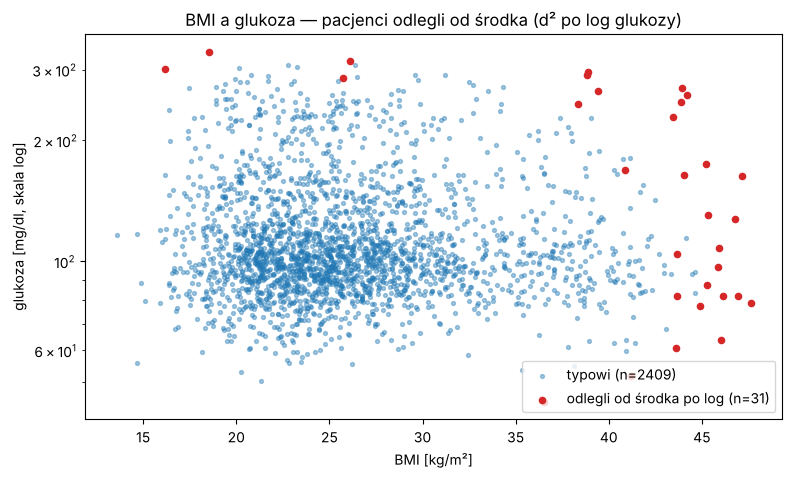

,age,bmi,avg_glucose_level
age,1.00,0.02,0.01
bmi,0.02,1.00,-0.02
avg_glucose_level,0.01,-0.02,1.00


In [24]:
X_log = X.copy()
X_log["avg_glucose_level"] = np.log(X_log["avg_glucose_level"])
Z_log = (X_log - X_log.mean()) / X_log.std()
d2_log = (Z_log ** 2).sum(axis=1)
odlegli_log = d2_log > prog

print("Odstający przed logarytmem:", odlegli.sum())
print("Odstający po logarytmie:  ", odlegli_log.sum())
print("Cecha o największym udziale po logarytmie:")
print((Z_log[odlegli_log] ** 2).idxmax(axis=1).value_counts())

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(X.loc[~odlegli_log, "bmi"], X.loc[~odlegli_log, "avg_glucose_level"], s=8, alpha=0.4,
           label=f"typowi (n={(~odlegli_log).sum()})")
ax.scatter(X.loc[odlegli_log, "bmi"], X.loc[odlegli_log, "avg_glucose_level"], s=20, color="tab:red",
           label=f"odlegli od środka po log (n={odlegli_log.sum()})")
ax.set_yscale("log")
ax.set_title("BMI a glukoza — pacjenci odlegli od środka (d² po log glukozy)")
ax.set_xlabel("BMI [kg/m²]")
ax.set_ylabel("glukoza [mg/dl, skala log]")
ax.legend()
plt.show()

X.corr()

✍️ **Pytanie:** Wiek, BMI i glukoza są tu prawie nieskorelowane (sprawdź `X.corr()`). Czy w takiej sytuacji odległość Mahalanobisa dałaby coś więcej niż euklidesowa?

*Odpowiedź:* Praktycznie nie. Korelacje są bliskie zera (|r| ≤ 0,02), więc macierz kowariancji standaryzowanych cech jest niemal jednostkowa, a odległość Mahalanobisa sprowadza się wtedy do euklidesowej na danych wystandaryzowanych — wyniki byłyby prawie identyczne. Mahalanobis daje przewagę dopiero przy skorelowanych cechach, gdy wykrywa punkty „wbrew korelacji” (np. wysoki wzrost przy bardzo małej masie), których odległość euklidesowa nie zauważy.

### Dla chętnych: Isolation Forest

Użyj `sklearn.ensemble.IsolationForest` (`contamination=0.01`, `random_state=0`) na `X_log`. Ilu pacjentów wskazuje jednocześnie Isolation Forest i odległość `d2_log`?

In [25]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.01, random_state=0)
iso_odst = pd.Series(iso.fit_predict(X_log) == -1, index=X_log.index)

print("Isolation Forest wskazuje:", iso_odst.sum())
print("d2_log wskazuje:          ", odlegli_log.sum())
print("Wspólnie:                 ", (iso_odst & odlegli_log).sum())

Isolation Forest wskazuje: 25
d2_log wskazuje:           31
Wspólnie:                  19


## 2.6 Krok 5: podsumowanie i decyzja

Zbierz wyniki wszystkich kroków w jednej ramce `flagi` (jeden wiersz na pacjenta, indeks jak w `oryginal`) z kolumnami logicznymi:

- `niemozliwa_wartosc` (krok 1),
- `glukoza_iqr` (krok 2, IQR 1,5 dla glukozy),
- `nielogiczna_kategoria` (krok 3),
- `odlegly_od_srodka` (krok 4, `d2_log`; pacjenci bez obliczonej odległości → `False`).

Policz, ilu pacjentów ma każdą flagę i ilu ma co najmniej jedną.

In [26]:
flagi = pd.DataFrame(index=oryginal.index)
flagi["niemozliwa_wartosc"] = zle_bmi | zla_glukoza | zly_wiek
flagi["glukoza_iqr"] = maska_iqr(pacjenci["avg_glucose_level"])
flagi["nielogiczna_kategoria"] = dziecko_pali | maluch_student
flagi["odlegly_od_srodka"] = odlegli_log.reindex(oryginal.index, fill_value=False)

podsumowanie = flagi.sum().to_frame("liczba pacjentów")
podsumowanie.loc["co najmniej jedna flaga"] = flagi.any(axis=1).sum()
podsumowanie

,liczba pacjentów
niemozliwa_wartosc,560
glukoza_iqr,235
nielogiczna_kategoria,16
odlegly_od_srodka,31
co najmniej jedna flaga,806


✍️ **Decyzja:** dla każdej grupy zaproponuj strategię i uzasadnij ją jednym zdaniem.

| Grupa | Strategia (poprawić / NaN / usunąć / przyciąć / log / zostawić / flaga) | Uzasadnienie |
|---|---|---|
| wartości niemożliwe | **NaN** (potem ewentualnie imputacja) | To powtarzające się kody błędów (−5,2; 0; 3,4; 105,6 dla BMI, −21,4; 0; 5; 1254,6 dla glukozy), a nie pomiary, więc nie da się ich poprawić — wymazujemy wartość, ale zachowujemy resztę informacji o pacjencie. |
| wysoka glukoza (IQR) | **zostawić + log** (ewentualnie flaga) | To możliwe biologicznie wartości i ~9% danych, które w realnych danych niosą informację o ryzyku udaru; logarytm tylko zmniejsza wpływ długiego ogona na modele. |
| nielogiczne kategorie | **poprawić / NaN** w `smoking_status` (lub `work_type`) + flaga | Błędna jest kombinacja, a nie cały rekord — dla dzieci najrozsądniej ustawić `smoking_status` na „never smoked” lub „Unknown”, a 1,8-latka-studenta przekwalifikować na `children`, i zostawić flagę do weryfikacji. |
| odlegli od środka | **zostawić + flaga** | Po logarytmie to tylko ~1% pacjentów (zgodnie z oczekiwaniem przy progu 0,99), ich wartości są możliwe i nieskorelowane ze sobą, więc są to prawdopodobnie rzadcy, ale prawdziwi pacjenci — flagujemy ich do kontroli zamiast usuwać. |